In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
df = pd.read_csv('zomato_data.csv')

In [5]:
df.head()

,name,online_order,book_table,rate,votes,approx_cost(for two people),listed_in(type)
0,Jalsa,Yes,Yes,4.1/5,775,800,Buffet
1,Spice Elephant,Yes,No,4.1/5,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8/5,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7/5,88,300,Buffet
4,Grand Village,No,No,3.8/5,166,600,Buffet


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   name                         148 non-null    object
 1   online_order                 148 non-null    object
 2   book_table                   148 non-null    object
 3   rate                         148 non-null    object
 4   votes                        148 non-null    int64 
 5   approx_cost(for two people)  148 non-null    int64 
 6   listed_in(type)              148 non-null    object
dtypes: int64(2), object(5)
memory usage: 8.2+ KB


In [9]:
def rate(value):
    value = str(value).split('/')
    value = value[0];
    return float(value)

df['rate'] = df['rate'].apply(rate)
df.head()

,name,online_order,book_table,rate,votes,approx_cost(for two people),listed_in(type)
0,Jalsa,Yes,Yes,4.1,775,800,Buffet
1,Spice Elephant,Yes,No,4.1,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7,88,300,Buffet
4,Grand Village,No,No,3.8,166,600,Buffet


In [10]:
df.isna().sum()

name                           0
online_order                   0
book_table                     0
rate                           0
votes                          0
approx_cost(for two people)    0
listed_in(type)                0
dtype: int64

In [11]:
df.duplicated().sum()

0

In [12]:
df['listed_in(type)'].value_counts()

listed_in(type)
Dining    110
Cafes      23
other       8
Buffet      7
Name: count, dtype: int64

Text(0.5, 1.0, 'Types of Restaurant listed in Zomato')

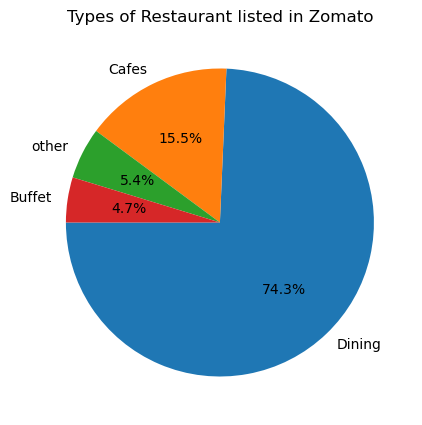

In [61]:
plt.figure(figsize = (5,5))
viz_1 = plt.pie(df['listed_in(type)'].value_counts(), labels = df['listed_in(type)'].value_counts().index,
        startangle = 180, autopct = '%1.1f%%')
plt.title('Types of Restaurant listed in Zomato')

In [25]:
most_fav_res = df.groupby(df['listed_in(type)'])['votes'].sum().reset_index()
most_fav_res

,listed_in(type),votes
0,Buffet,3028
1,Cafes,6434
2,Dining,20363
3,other,9367


[Text(0.5, 1.0, 'Most Favored Types of Restaurant'),
 Text(0.5, 0, 'Type of Restaurant'),
 Text(0, 0.5, 'No Votes')]

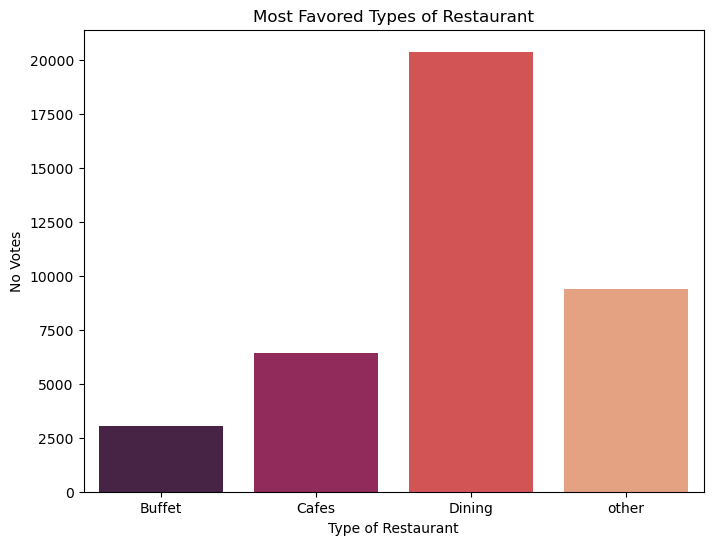

In [60]:
plt.figure(figsize = (8,6))
viz_2 = sns.barplot(most_fav_res, x = 'listed_in(type)', y = 'votes', palette = 'rocket')
viz_2.set(title = 'Most Favored Types of Restaurant', xlabel = 'Type of Restaurant', ylabel = 'No Votes')

[Text(0.5, 1.0, 'Most Voted Restaurants by Types '),
 Text(0.5, 0, 'Restaurents'),
 Text(0, 0.5, 'Votes ')]

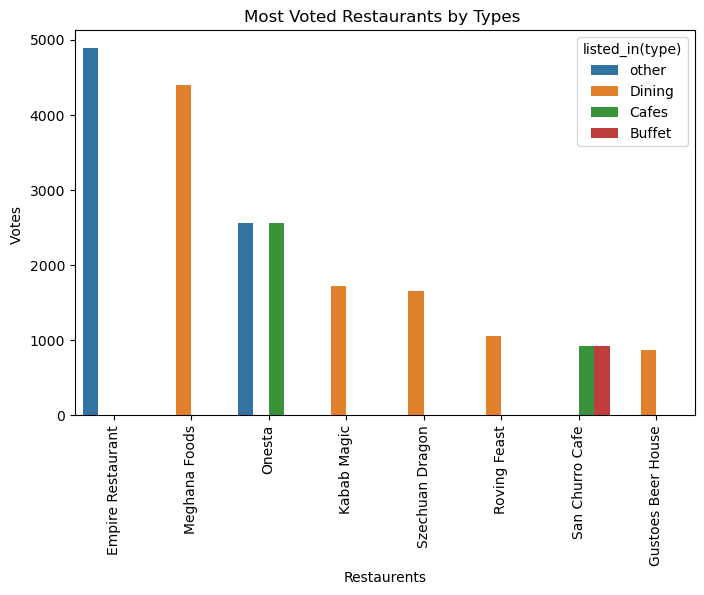

In [62]:
top_res = df.nlargest(10, columns  = 'votes')
plt.figure(figsize = (8,5))
viz_3 = sns.barplot(top_res, x = 'name', y = 'votes', hue = 'listed_in(type)')
viz_3.set_xticklabels(viz_3.get_xticklabels(), rotation = 90)
viz_3.set(title = 'Most Voted Restaurants by Types ', xlabel = 'Restaurents', ylabel = 'Votes ')

Text(0.5, 1.0, 'Online order by Restaurants')

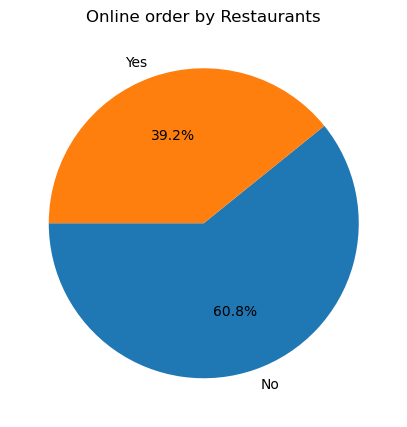

In [69]:
df['online_order'].value_counts()
plt.figure(figsize = (5,8))
plt.pie(df['online_order'].value_counts(), labels = df['online_order'].value_counts().index, startangle = 180, autopct = '%1.1f%%')
plt.title('Online order by Restaurants')

C:\Users\sarfa\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


<Figure size 500x800 with 0 Axes>

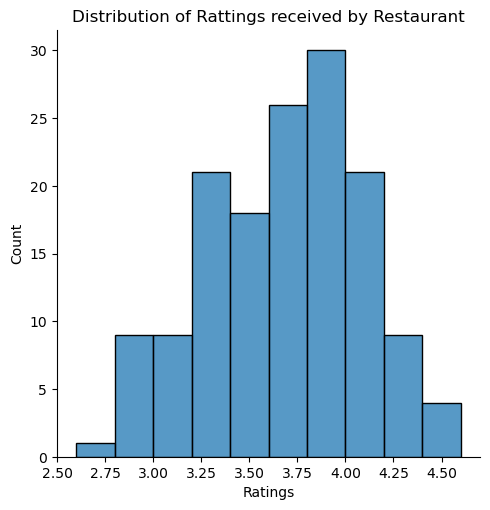

In [82]:
plt.figure(figsize = (5,8))
viz_4 = sns.displot(df['rate'], bins = 10)
viz_4.set(title = 'Distribution of Rattings received by Restaurant', xlabel = 'Ratings')


In [84]:
df['approx_cost(for two people)'].value_counts()

approx_cost(for two people)
300    23
200    16
150    16
400    15
500    14
600    13
800    12
100     6
450     6
250     6
700     5
550     3
750     3
350     3
900     2
850     2
650     2
950     1
Name: count, dtype: int64

[Text(0.5, 1.0, 'Price preferred by Couples'),
 Text(0.5, 0, 'Approx price for Couples')]

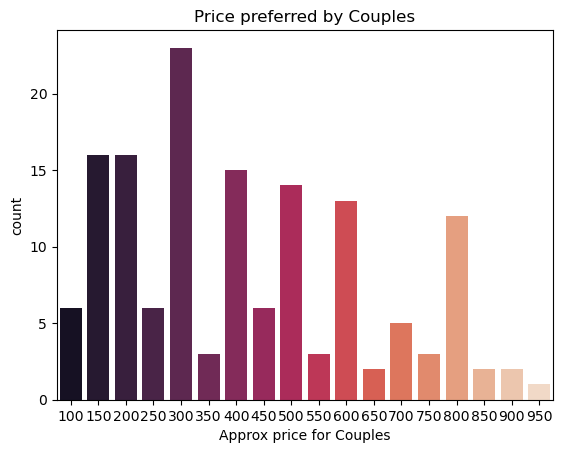

In [91]:
viz_5 = sns.countplot(x = df['approx_cost(for two people)'], palette = 'rocket')
viz_5.set(title = 'Price preferred by Couples', xlabel = 'Approx price for Couples')

In [94]:
df.groupby(df['online_order'])['rate'].max()

online_order
No     4.3
Yes    4.6
Name: rate, dtype: float64

In [95]:
df.pivot_table(index='listed_in(type)', columns='online_order', aggfunc='size', fill_value=0)

online_order,No,Yes
listed_in(type),,
Buffet,3,4
Cafes,8,15
Dining,77,33
other,2,6
